# Instance Segmentation: Panoptic Indoor v5
**Variabel NRP (digit terakhir 1): ukuran input 320 / 640 / 960**

| Model | Keluarga | Ukuran input |
|---|---|---|
| YOLO11s-seg | one-stage, CNN | 320, 640, 960 |
| YOLOv8s-seg | one-stage, CNN | 640 |
| Mask R-CNN (R50-FPN v2) | two-stage, CNN | 640 |

In [1]:
# ===== KONFIGURASI =====
SMOKE_TEST  = False
SIZES       = [320, 640, 960]
BASE_SIZE   = 640
EPOCHS      = 100
TIME_HOURS  = 1.8
PRETRAINED  = True
SEED        = 42
RUN_MASKRCNN_ALL_SIZES = False

BATCH_YOLO = {320: 32, 640: 16, 960: 8}
BATCH_RCNN = {320: 8,  640: 4,  960: 2}

if SMOKE_TEST:
    EPOCHS, TIME_HOURS = 1, 0.05

In [2]:
!pip -q install roboflow ultralytics pycocotools

import os, json, time, shutil, csv, random
import numpy as np
from pathlib import Path
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

SAVE_DIR = "/kaggle/working/saved_runs" + ("_smoke" if SMOKE_TEST else "")
os.makedirs(SAVE_DIR, exist_ok=True)

RES_PATH = f"{SAVE_DIR}/results_summary.json"
RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def log_result(key, **kw):
    RESULTS.setdefault(key, {}).update(kw)
    json.dump(RESULTS, open(RES_PATH, "w"), indent=1)

import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
cfg = dict(SMOKE_TEST=SMOKE_TEST, SIZES=SIZES, BASE_SIZE=BASE_SIZE, EPOCHS=EPOCHS, TIME_HOURS=TIME_HOURS,
           PRETRAINED=PRETRAINED, SEED=SEED, BATCH_YOLO=BATCH_YOLO, BATCH_RCNN=BATCH_RCNN, GPU=gpu)
json.dump(cfg, open(f"{SAVE_DIR}/config.json", "w"), indent=1)
print("GPU:", gpu); print(cfg)

rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))
project = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation")
version = project.version(5)
version.download("coco-segmentation", location="/kaggle/working/dataset_coco")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
GPU: Tesla T4
{'SMOKE_TEST': False, 'SIZES': [320, 640, 960], 'BASE_SIZE': 640, 'EPOCHS': 100, 'TIME_HOURS': 1.8, 'PRETRAINED': True, 'SEED': 42, 'BATCH_YOLO': {320: 32, 640: 16, 960: 8}, 'BATCH_RCNN': {320: 8, 640: 4, 960: 2}, 'GPU': 'Tesla T4'}
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset_coco in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 7344.79it/s]


## Data: cek dan konversi COCO -> format YOLO-seg

In [3]:
ROOT = "/kaggle/working/dataset_coco"
coco = json.load(open(f"{ROOT}/train/_annotations.coco.json"))
print(len(coco["images"]), "gambar train,", len(coco["annotations"]), "anotasi")
print("Contoh polygon:", str(coco["annotations"][0]["segmentation"])[:100])

used = sorted({a["category_id"] for a in coco["annotations"]})
cats = {c["id"]: c["name"] for c in coco["categories"]}
NAMES = [cats[c] for c in used]
name2idx = {n: i for i, n in enumerate(NAMES)}
print(len(NAMES), "kelas aktif")

def coco_to_yolo_seg(src, dst):
    src, dst = Path(src), Path(dst)
    d = json.load(open(src / "_annotations.coco.json"))
    cid2idx = {c["id"]: name2idx[c["name"]] for c in d["categories"] if c["name"] in name2idx}
    (dst / "images").mkdir(parents=True, exist_ok=True)
    (dst / "labels").mkdir(parents=True, exist_ok=True)
    imgs = {im["id"]: im for im in d["images"]}
    lines = {i: [] for i in imgs}
    for a in d["annotations"]:
        if a["category_id"] not in cid2idx or not isinstance(a["segmentation"], list):
            continue
        im = imgs[a["image_id"]]; w, h = im["width"], im["height"]
        for seg in a["segmentation"]:
            if len(seg) < 6:
                continue
            pts = [f"{seg[i]/w:.6f} {seg[i+1]/h:.6f}" for i in range(0, len(seg), 2)]
            lines[a["image_id"]].append(f"{cid2idx[a['category_id']]} " + " ".join(pts))
    for iid, im in imgs.items():
        shutil.copy(src / im["file_name"], dst / "images" / im["file_name"])
        (dst / "labels" / (Path(im["file_name"]).stem + ".txt")).write_text("\n".join(lines[iid]))

def write_yaml(path, root, only_test=False):
    with open(path, "w") as f:
        if only_test:
            f.write(f"path: {root}\ntrain: test/images\nval: test/images\ntest: test/images\n")
        else:
            f.write(f"path: {root}\ntrain: train/images\nval: valid/images\ntest: test/images\n")
        f.write(f"nc: {len(NAMES)}\nnames: {NAMES}\n")

for split in ["train", "valid", "test"]:
    coco_to_yolo_seg(f"{ROOT}/{split}", f"/kaggle/working/dataset_yolo/{split}")
DATA_YAML = "/kaggle/working/dataset_yolo/data.yaml"
write_yaml(DATA_YAML, "/kaggle/working/dataset_yolo")

397 gambar train, 4479 anotasi
Contoh polygon: [[145, 459.375, 191.875, 450, 219.375, 436.25, 238.75, 416.875, 263.75, 373.125, 261.25, 359.375, 24
65 kelas aktif


## YOLO-seg (Ultralytics)
Training berjalan tepat `EPOCHS` epoch (tidak memakai batas waktu). Hasil tiap run disalin ke `saved_runs/` beserta `results.csv`.

In [4]:
from ultralytics import YOLO

W = lambda n: f"{n}.pt" if PRETRAINED else f"{n}.yaml"

def eval_yolo(name, imgsz, data_yaml=DATA_YAML, split="test"):
    m = YOLO(f"{SAVE_DIR}/{name}/weights/best.pt")
    r = m.val(data=data_yaml, split=split, imgsz=imgsz, device=0, plots=False, verbose=False)
    return float(r.seg.map), float(r.seg.map50), float(r.speed["inference"])

def run_yolo(weights, tag, imgsz, batch):
    name = f"{tag}_{imgsz}"
    if not os.path.exists(f"{SAVE_DIR}/{name}/weights/best.pt"):
        t0 = time.time()
        YOLO(weights).train(data=DATA_YAML, imgsz=imgsz, epochs=EPOCHS, batch=batch, device=0,
                            seed=SEED, patience=EPOCHS, workers=4, pretrained=PRETRAINED,
                            project="/kaggle/working/runs", name=name, exist_ok=True)
        mins = (time.time() - t0) / 60
        shutil.copytree(f"/kaggle/working/runs/{name}", f"{SAVE_DIR}/{name}", dirs_exist_ok=True)
        log_result(name, model=tag, imgsz=imgsz, train_min=round(mins, 1))
        print(f"[{name}] waktu training: {mins:.1f} menit")
    else:
        print(f"[{name}] sudah ada di saved_runs, training dilewati")
    mp, mp50, ms = eval_yolo(name, imgsz)
    log_result(name, model=tag, imgsz=imgsz, test_map=round(mp, 4), test_map50=round(mp50, 4), infer_ms=round(ms, 1))
    print(f"[{name}] test asli: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}  inferensi={ms:.1f} ms/gambar")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### Nyoba YoloV11s-seg

In [5]:
SIZES_NOW = SIZES
for sz in SIZES_NOW:
    run_yolo(W("yolo11s-seg"), "yolo11s_seg", sz, BATCH_YOLO[sz])

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_seg_320, nbs=64, nms=None, opset=None

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/100      3.07G      1.261      2.917      3.933      1.357          0        338        320: 100% ━━━━━━━━━━━━ 13/13 3.0it/s 4.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.6s1.2s
                   all        166       2020      0.422      0.135      0.134        0.1      0.387      0.138      0.129     0.0727

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      3.07G      1.171      2.562      3.277      1.299          0        266        320: 100% ━━━━━━━━━━━━ 13/13 3.3it/s 3.9s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7it/s 1.8s1.3s
                   all        166       2020        0.3        0.2      0.127      0.096      0.297      0.192      0.124     0.0798

  

### Nyoba Yolov8s-seg

In [6]:
run_yolo(W("yolov8s-seg"), "yolov8s_seg", BASE_SIZE, BATCH_YOLO[BASE_SIZE])

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_seg_640, nbs=64, nms=None, opset=None

## Mask R-CNN (torchvision, R50-FPN v2)

In [7]:
from PIL import Image
from pycocotools.coco import COCO
from pycocotools import mask as mask_util
from pycocotools.cocoeval import COCOeval
import torchvision.transforms.functional as TF
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

dev = "cuda"
NC = len(NAMES) + 1

class CocoSeg(torch.utils.data.Dataset):
    def __init__(self, split_dir, train=False):
        self.dir = split_dir
        self.coco = COCO(f"{split_dir}/_annotations.coco.json")
        self.ids = sorted(self.coco.imgs.keys())
        self.train = train
        # pemetaan via nama kelas -> label 1..N (0 = background)
        self.cid2lab = {c["id"]: name2idx[c["name"]] + 1 for c in self.coco.dataset["categories"] if c["name"] in name2idx}
        self.lab2cid = {v: k for k, v in self.cid2lab.items()}
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]; info = self.coco.imgs[iid]
        img = Image.open(f"{self.dir}/{info['file_name']}").convert("RGB")
        W_, H_ = img.size
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=iid, iscrowd=False))
        boxes, labels, masks = [], [], []
        for a in anns:
            if a["category_id"] not in self.cid2lab: continue
            x, y, w, h = a["bbox"]
            if w < 2 or h < 2: continue
            boxes.append([x, y, x + w, y + h]); labels.append(self.cid2lab[a["category_id"]])
            masks.append(self.coco.annToMask(a))
        img = TF.to_tensor(img)
        if boxes:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)
            masks = torch.from_numpy(np.stack(masks)).to(torch.uint8)
        else:
            boxes = torch.zeros((0, 4)); labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros((0, H_, W_), dtype=torch.uint8)
        if self.train and torch.rand(1).item() < 0.5:
            img = img.flip(-1); masks = masks.flip(-1)
            if len(boxes):
                boxes = torch.stack([W_ - boxes[:, 2], boxes[:, 1], W_ - boxes[:, 0], boxes[:, 3]], 1)
        return img, {"boxes": boxes, "labels": labels, "masks": masks}, iid

def collate(b): return tuple(zip(*b))

def build_maskrcnn(imgsz):
    kw = dict(min_size=imgsz, max_size=imgsz)
    if PRETRAINED:
        model = maskrcnn_resnet50_fpn_v2(weights="DEFAULT", **kw)
    else:
        model = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, **kw)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, NC)
    in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, NC)
    return model.to(dev)

def load_maskrcnn(imgsz):
    model = build_maskrcnn(imgsz)
    model.load_state_dict(torch.load(f"{SAVE_DIR}/maskrcnn_{imgsz}/last.pt", map_location=dev))
    return model.eval()

def train_maskrcnn(imgsz, batch, lr=0.005):
    torch.manual_seed(SEED)
    ds = CocoSeg(f"{ROOT}/train", train=True)
    dl = torch.utils.data.DataLoader(ds, batch_size=batch, shuffle=True, collate_fn=collate, num_workers=2)
    model = build_maskrcnn(imgsz)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler()
    warm = min(200, max(len(dl) - 1, 1))
    it = 0; t0 = time.time(); rows = []; stop = False
    for ep in range(EPOCHS):
        model.train(); tot = 0.0; n = 0
        for imgs, tg, _ in dl:
            if it < warm:
                f = 0.001 + 0.999 * it / warm
                for g in opt.param_groups: g["lr"] = lr * f
            it += 1
            imgs = [i.to(dev) for i in imgs]
            tg = [{k: v.to(dev) for k, v in t.items()} for t in tg]
            with torch.autocast("cuda"):
                loss = sum(model(imgs, tg).values())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); n += 1
            if time.time() - t0 > TIME_HOURS * 3600: stop = True; break
        sched.step()
        rows.append([ep + 1, tot / max(n, 1), (time.time() - t0) / 60])
        print(f"epoch {ep+1}/{EPOCHS}  loss={tot/max(n,1):.4f}  {rows[-1][2]:.1f} menit")
        if stop: print("Batas waktu tercapai, training dihentikan."); break
    out = Path(f"{SAVE_DIR}/maskrcnn_{imgsz}"); out.mkdir(parents=True, exist_ok=True)
    with open(out / "results.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["epoch", "train_loss", "menit_kumulatif"]); w.writerows(rows)
    torch.save(model.state_dict(), out / "last.pt")
    return model.eval(), (time.time() - t0) / 60

@torch.no_grad()
def eval_maskrcnn(model, split_dir):
    ds = CocoSeg(split_dir)
    dl = torch.utils.data.DataLoader(ds, batch_size=4, collate_fn=collate, num_workers=2)
    model.eval(); results = []; sec = 0.0
    for imgs, _, iids in dl:
        imgs = [i.to(dev) for i in imgs]
        torch.cuda.synchronize(); t = time.time()
        out = model(imgs)
        torch.cuda.synchronize(); sec += time.time() - t
        for o, iid in zip(out, iids):
            for m, l, s in zip(o["masks"], o["labels"], o["scores"]):
                cid = ds.lab2cid.get(int(l))
                if cid is None: continue
                b = (m[0] > 0.5).cpu().numpy().astype(np.uint8)
                rle = mask_util.encode(np.asfortranarray(b)); rle["counts"] = rle["counts"].decode()
                results.append({"image_id": iid, "category_id": cid, "segmentation": rle, "score": float(s)})
    ms = 1000 * sec / len(ds)
    if not results:
        print("Tidak ada prediksi."); return 0.0, 0.0, ms
    E = COCOeval(ds.coco, ds.coco.loadRes(results), "segm")
    E.params.catIds = list(ds.cid2lab.keys())
    E.evaluate(); E.accumulate(); E.summarize()
    return float(E.stats[0]), float(E.stats[1]), ms

def run_maskrcnn(imgsz):
    name = f"maskrcnn_{imgsz}"
    if not os.path.exists(f"{SAVE_DIR}/{name}/last.pt"):
        model, mins = train_maskrcnn(imgsz, BATCH_RCNN[imgsz])
        log_result(name, model="maskrcnn", imgsz=imgsz, train_min=round(mins, 1))
        print(f"[{name}] waktu training: {mins:.1f} menit")
    else:
        print(f"[{name}] sudah ada di saved_runs, training dilewati")
        model = load_maskrcnn(imgsz)
    mp, mp50, ms = eval_maskrcnn(model, f"{ROOT}/test")
    log_result(name, model="maskrcnn", imgsz=imgsz, test_map=round(mp, 4), test_map50=round(mp50, 4), infer_ms=round(ms, 1))
    print(f"[{name}] test asli: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}  inferensi={ms:.1f} ms/gambar")
    del model; torch.cuda.empty_cache()

In [8]:
for sz in (SIZES if RUN_MASKRCNN_ALL_SIZES else [BASE_SIZE]):
    run_maskrcnn(sz)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 238MB/s] 


epoch 1/100  loss=3.0998  0.8 menit
epoch 2/100  loss=1.9461  1.6 menit
epoch 3/100  loss=1.5750  2.3 menit
epoch 4/100  loss=1.3640  3.1 menit
epoch 5/100  loss=1.2095  3.9 menit
epoch 6/100  loss=1.0913  4.6 menit
epoch 7/100  loss=0.9958  5.4 menit
epoch 8/100  loss=0.9424  6.2 menit
epoch 9/100  loss=0.8752  6.9 menit
epoch 10/100  loss=0.7953  7.7 menit
epoch 11/100  loss=0.7295  8.5 menit
epoch 12/100  loss=0.7191  9.2 menit
epoch 13/100  loss=0.6514  10.0 menit
epoch 14/100  loss=0.6193  10.8 menit
epoch 15/100  loss=0.6022  11.5 menit
epoch 16/100  loss=0.5641  12.3 menit
epoch 17/100  loss=0.5212  13.1 menit
epoch 18/100  loss=0.4984  13.9 menit
epoch 19/100  loss=0.4869  14.6 menit
epoch 20/100  loss=0.4703  15.4 menit
epoch 21/100  loss=0.4474  16.2 menit
epoch 22/100  loss=0.4390  16.9 menit
epoch 23/100  loss=0.4368  17.7 menit
epoch 24/100  loss=0.4326  18.5 menit
epoch 25/100  loss=0.4286  19.2 menit
epoch 26/100  loss=0.3952  20.0 menit
epoch 27/100  loss=0.3783  20.8 m

## Evaluasi di train set dan valid set (cek overfitting)
Tiap model dievaluasi di split train dan valid. Selisih train vs test menunjukkan seberapa besar model menghafal data latih.

In [9]:
def eval_split(name, info, split):
    if info["model"] == "maskrcnn":
        model = load_maskrcnn(info["imgsz"])
        mp, mp50, _ = eval_maskrcnn(model, f"{ROOT}/{split}")
        del model; torch.cuda.empty_cache()
    else:
        mp, mp50, _ = eval_yolo(name, info["imgsz"], DATA_YAML,
                                split={"train": "train", "valid": "val"}[split])
    return mp, mp50

for name, info in list(RESULTS.items()):
    if "train_min" not in info:
        continue
    for split in ["train", "valid"]:
        if f"{split}_map" in info:
            continue
        mp, mp50 = eval_split(name, info, split)
        log_result(name, **{f"{split}_map": round(mp, 4), f"{split}_map50": round(mp50, 4)})
        print(f"[{name}] {split}: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1207.8±297.5 MB/s, size: 34.4 KB)
val: Scanning /kaggle/working/dataset_yolo/train/labels.cache... 397 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 397/397 79.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.9it/s 3.6s0.1s
                   all        397       4479      0.814      0.759      0.825      0.701      0.804      0.742      0.804      0.593
Speed: 0.2ms preprocess, 2.5ms inference, 0.0ms loss, 1.6ms postprocess per image
[yolo11s_seg_320] train: mask mAP50-95=0.5932  mAP50=0.8044
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0

## Kurva training
Dari `results.csv` tiap run: kurva mask mAP per epoch (YOLO) dan loss per epoch (Mask R-CNN). Berguna sebagai bukti log training dan untuk melihat apakah model sudah konvergen.

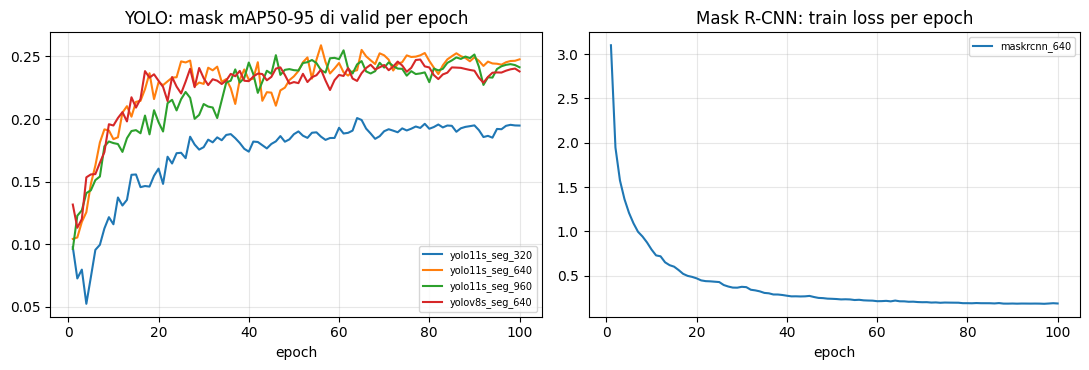

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in sorted(RESULTS):
    p = f"{SAVE_DIR}/{name}/results.csv"
    if not os.path.exists(p): continue
    d = pd.read_csv(p); d.columns = d.columns.str.strip()
    if name.startswith("maskrcnn"):
        ax[1].plot(d["epoch"], d["train_loss"], label=name)
    elif "metrics/mAP50-95(M)" in d.columns:
        ax[0].plot(d["epoch"], d["metrics/mAP50-95(M)"], label=name)
ax[0].set_title("YOLO: mask mAP50-95 di valid per epoch"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].set_title("Mask R-CNN: train loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/kurva_training.png", dpi=150, bbox_inches="tight"); plt.show()

## Visualisasi prediksi
Kolom pertama = ground truth (anotasi asli), kolom lain = prediksi tiap model. Warna dan nama kelas sama di semua kolom. Fungsi ini juga dipakai untuk test set buatanmu (untuk analisis kegagalan).

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


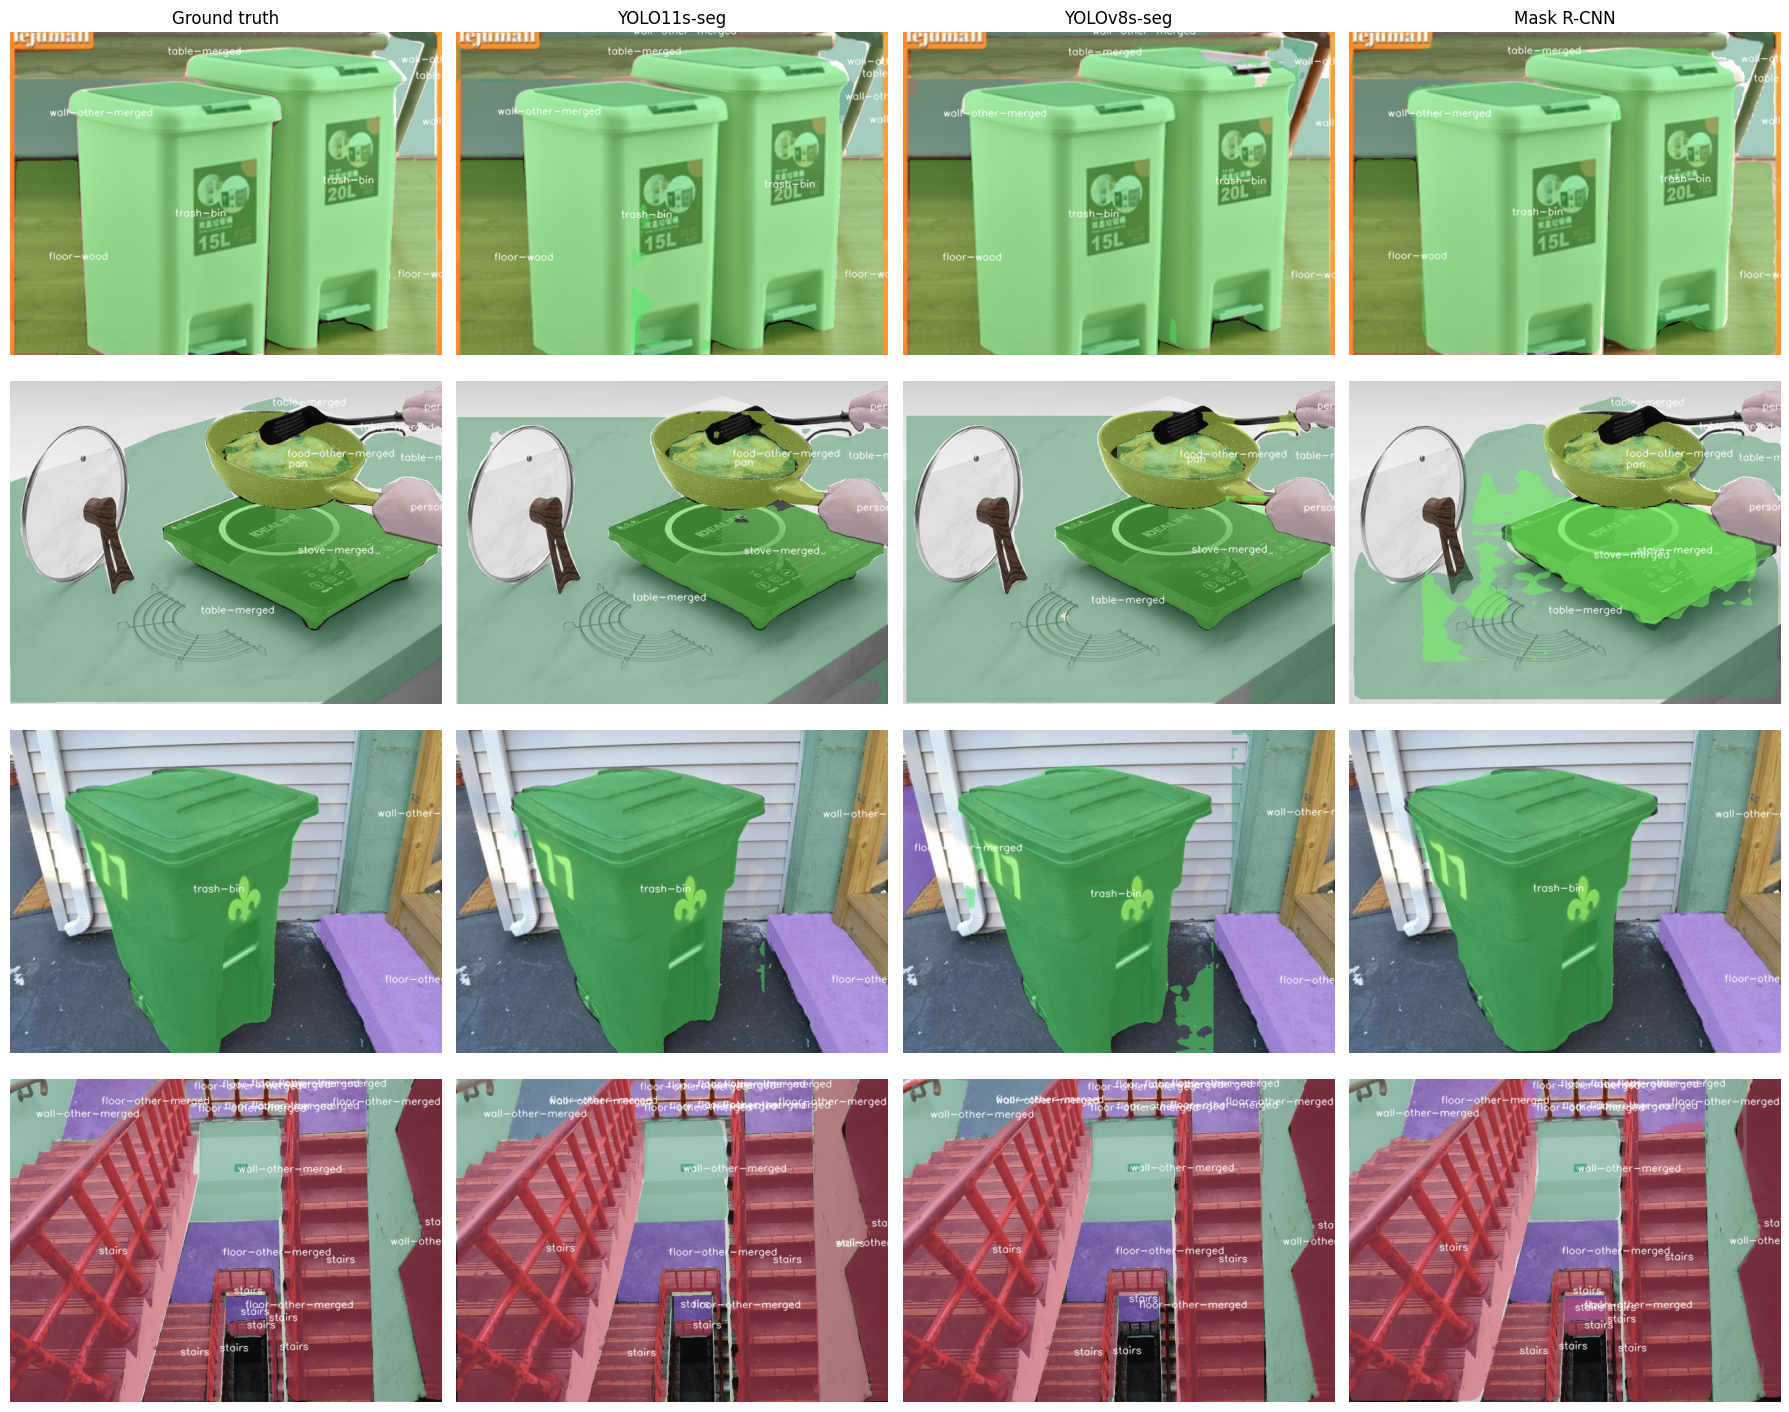

loading annotations into memory...
Done (t=0.05s)
creating index...
index created!


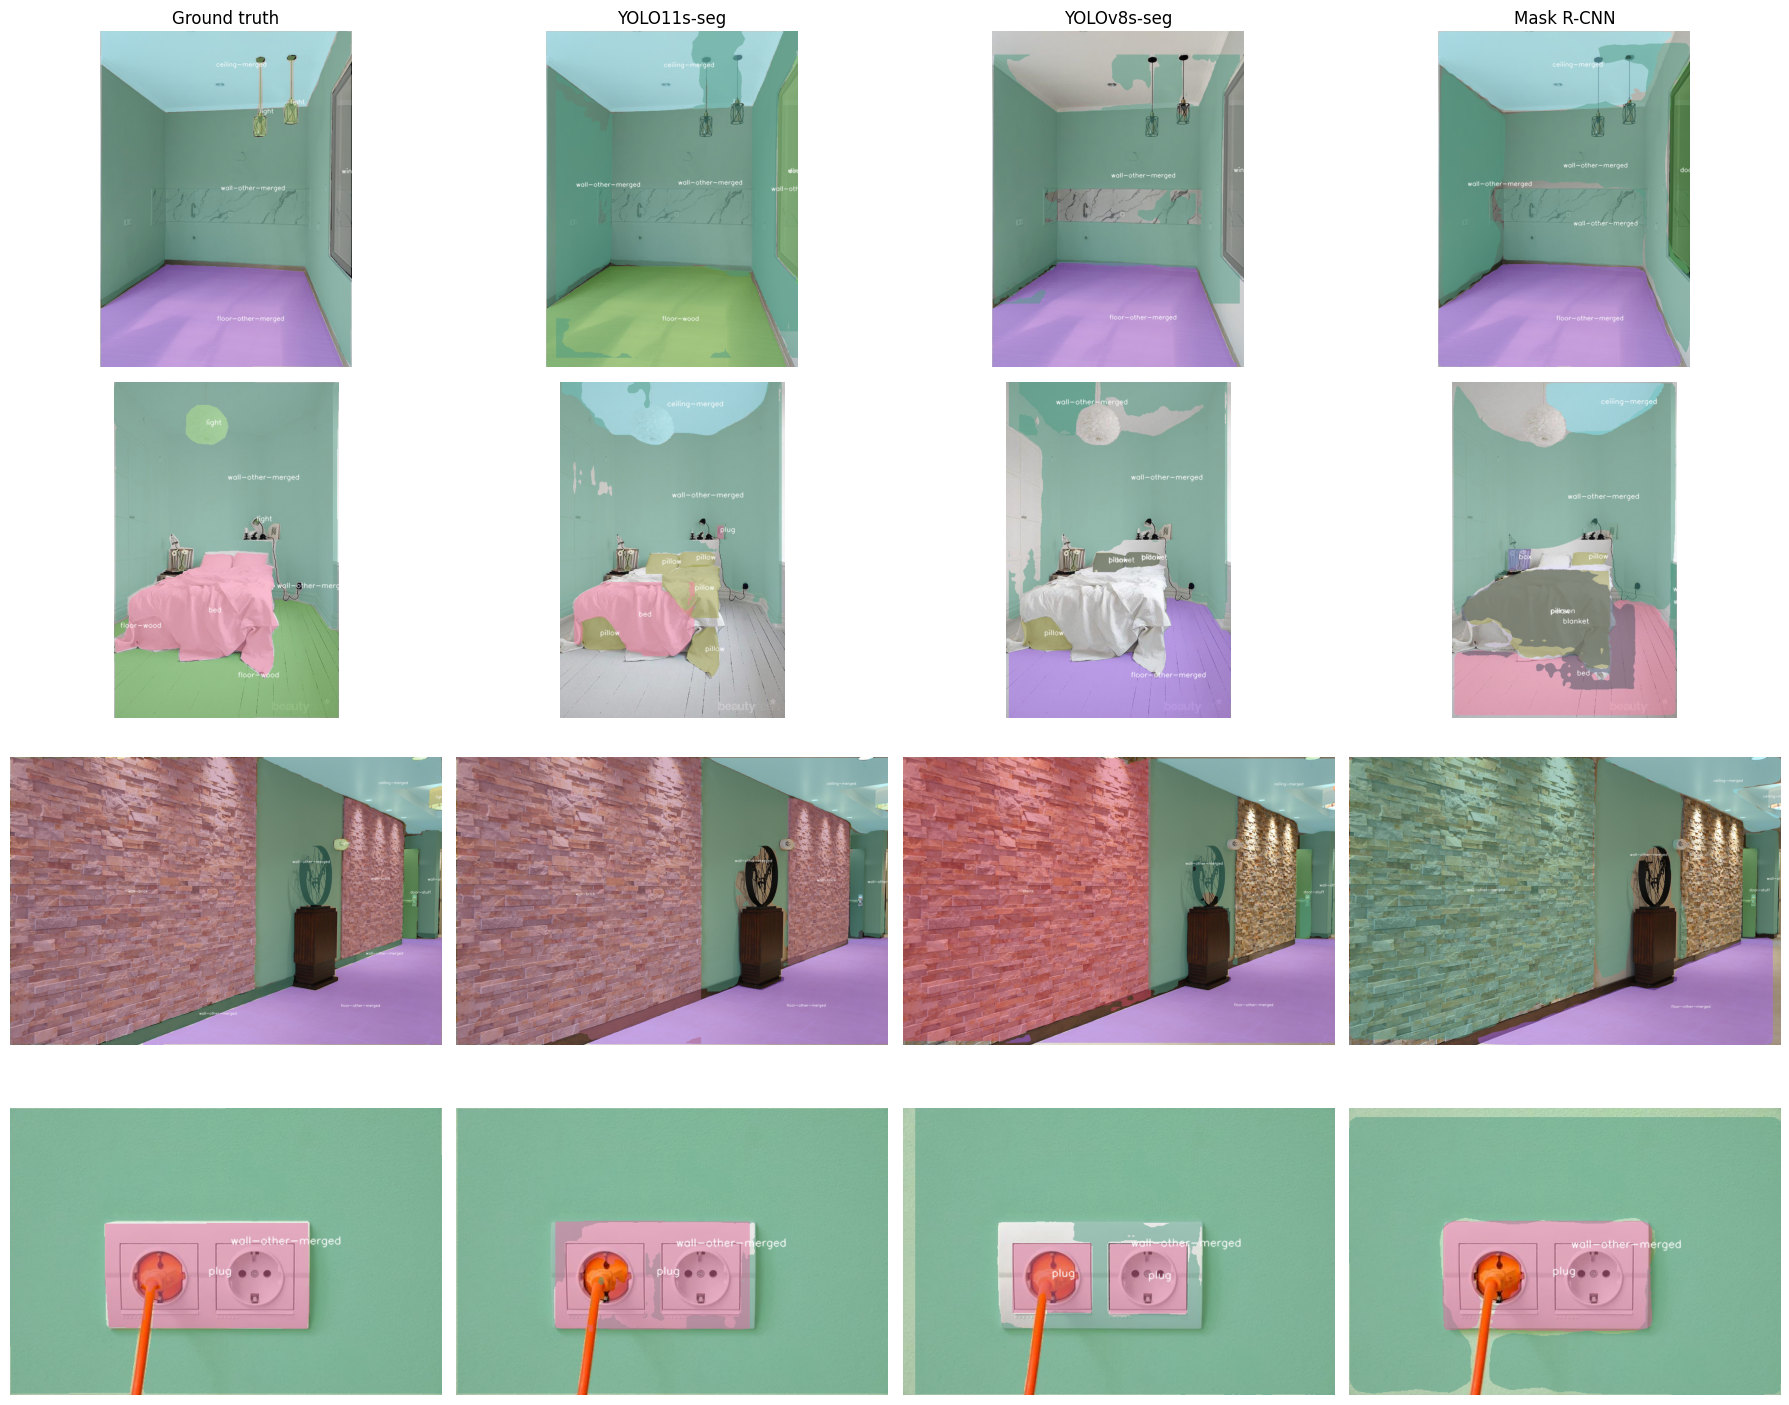

In [11]:
import cv2
import matplotlib.pyplot as plt

PALETTE = np.random.RandomState(0).randint(60, 255, (len(NAMES), 3))   # warna tetap per kelas

def overlay(img, masks, idxs, alpha=0.5):
    out = img.astype(np.float32).copy()
    for m, k in zip(masks, idxs):
        m = m > 0
        if m.any():
            out[m] = (1 - alpha) * out[m] + alpha * PALETTE[k]
    out = out.astype(np.uint8)
    for m, k in zip(masks, idxs):
        ys, xs = np.where(m > 0)
        if len(xs):
            cv2.putText(out, NAMES[k], (int(xs.mean()), int(ys.mean())),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    return out

def visualize(split_dir, tag, n=4, size=BASE_SIZE, seed=SEED, conf=0.25):
    gt = COCO(f"{split_dir}/_annotations.coco.json")
    cid2idx = {c["id"]: name2idx[c["name"]] for c in gt.dataset["categories"] if c["name"] in name2idx}
    yolos = {}
    for t, title in [("yolo11s_seg", "YOLO11s-seg"), ("yolov8s_seg", "YOLOv8s-seg")]:
        p = f"{SAVE_DIR}/{t}_{size}/weights/best.pt"
        if os.path.exists(p): yolos[title] = YOLO(p)
    rcnn = load_maskrcnn(size) if os.path.exists(f"{SAVE_DIR}/maskrcnn_{size}/last.pt") else None
    cols = ["Ground truth"] + list(yolos) + (["Mask R-CNN"] if rcnn else [])
    ids = random.Random(seed).sample(sorted(gt.imgs), min(n, len(gt.imgs)))
    fig, axes = plt.subplots(len(ids), len(cols), figsize=(4.5 * len(cols), 3.6 * len(ids)), squeeze=False)
    for r, iid in enumerate(ids):
        path = f"{split_dir}/{gt.imgs[iid]['file_name']}"
        img = np.array(Image.open(path).convert("RGB"))
        anns = [a for a in gt.loadAnns(gt.getAnnIds(imgIds=iid, iscrowd=False)) if a["category_id"] in cid2idx]
        row = [overlay(img, [gt.annToMask(a) for a in anns], [cid2idx[a["category_id"]] for a in anns])]
        for m in yolos.values():
            res = m.predict(path, imgsz=size, conf=conf, device=0, retina_masks=True, verbose=False)[0]
            if res.masks is None: row.append(img)
            else: row.append(overlay(img, res.masks.data.cpu().numpy(), res.boxes.cls.int().cpu().tolist()))
        if rcnn:
            with torch.no_grad():
                o = rcnn([TF.to_tensor(Image.fromarray(img)).to(dev)])[0]
            keep = o["scores"] > 0.5
            row.append(overlay(img, (o["masks"][keep][:, 0] > 0.5).cpu().numpy(), [int(l) - 1 for l in o["labels"][keep]]))
        for c, im in enumerate(row):
            axes[r][c].imshow(im); axes[r][c].axis("off")
            if r == 0: axes[r][c].set_title(cols[c])
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/visualisasi_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()
    if rcnn: del rcnn; torch.cuda.empty_cache()

visualize(f"{ROOT}/train", "train")
visualize(f"{ROOT}/test", "test")

In [12]:
from collections import Counter

# daftar kelas yang dipakai model (65 kelas)
print(len(NAMES))
for i, n in enumerate(NAMES):
    print(i, n)

# jumlah instance per kelas di train set
cnt = Counter(cats[a["category_id"]] for a in coco["annotations"])
for name, c in cnt.most_common():
    print(f"{c:5d}  {name}")

65
0 backpack
1 bed
2 blanket
3 book
4 bottle
5 bowl
6 box
7 cabinet-merged
8 cardboard
9 ceiling-merged
10 cell phone
11 chair
12 clock
13 couch
14 counter
15 cup
16 curtain
17 dining table
18 door-stuff
19 fire-extinguisher
20 floor-other-merged
21 floor-wood
22 food-other-merged
23 fork
24 handbag
25 knife
26 laptop
27 light
28 microwave
29 mirror-stuff
30 oven
31 pan
32 paper
33 paper-merged
34 person
35 pillow
36 plate
37 plug
38 potted plant
39 refrigerator
40 remote
41 rug-merged
42 shelf
43 sink
44 spoon
45 st-
46 stairs
47 stove-merged
48 table-merged
49 toilet
50 towel
51 toy
52 trash-bin
53 tree-merged
54 tv
55 vase
56 wall
57 wall-brick
58 wall-other-merged
59 wall-stone
60 wall-tile
61 wall-wood
62 wallet
63 window-blind
64 window-other
  756  wall-other-merged
  319  table-merged
  261  floor-other-merged
  225  pan
  217  chair
  217  toy
  197  wallet
  192  person
  175  stairs
  153  trash-bin
  127  food-other-merged
  105  book
  102  counter
   99  floor-wood
   97

In [13]:
print([c["name"] for c in coco["categories"]])

['indoor-objects', 'backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch', 'counter', 'cup', 'curtain', 'dining table', 'door-stuff', 'fire-extinguisher', 'floor-other-merged', 'floor-wood', 'flower', 'food-other-merged', 'fork', 'hair drier', 'handbag', 'keyboard', 'knife', 'laptop', 'light', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'person', 'pillow', 'plate', 'plug', 'potted plant', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stairs', 'stove-merged', 'table-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'trash-bin', 'tree-merged', 'tv', 'vase', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'wallet', 'window-blind', 'window-other']
